# HW2：Multiple Linear Regression（19 個原始特徵完整版）

**研究題目：**利用多元線性迴歸預測學生考試成績  
**學號：**7115064197  
**Kaggle：**[Student Performance Factors](https://www.kaggle.com/datasets/lainguyn123/student-performance-factors)  
**預測目標：**`Exam_Score`；使用其餘 **19 個原始欄位** 作為候選輸入。  

> 由原始上傳版本改寫。請先將 `StudentPerformanceFactors.csv` 上傳 Colab（或放在筆記本相同執行資料夾），再依序「執行階段 → 全部執行」。本修訂版沒有在未提供 CSV 時捏造新結果。類別編碼後的數值欄位數可能大於 19，特徵數的統計以**原始欄位群組**為準。

## 1. Business Understanding（商業理解）

目標是根據讀書時間、出席率、家庭及學習環境等學生資料，以多元線性迴歸預測 `Exam_Score`。比較完整 19 欄位基準模型，以及兩種選取 **15 個原始特徵** 的模型。此研究是預測性分析，不代表相關因素具有因果關係。

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_selection import f_regression
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
print('套件載入成功。')

套件載入成功。


## 2. Data Understanding（資料理解）

檢查資料來源、原始欄位數、欄位型態、缺失值、重複值及目標分布。資料來源為 Kaggle 公開 Dataset，**不是此研究實際參加的排行榜競賽**，因此不宣稱 Kaggle 名次。

In [4]:
# Colab 可先點左側資料夾上傳 CSV；也可取消註解以下兩行使用對話框。
# from google.colab import files
# uploaded = files.upload()

candidates = ['/content/StudentPerformanceFactors.csv', 'StudentPerformanceFactors.csv']
csv_path = next((p for p in candidates if os.path.isfile(p)), None)
if csv_path is None:
    raise FileNotFoundError('找不到 StudentPerformanceFactors.csv：請先在 Colab 左側檔案區上傳 CSV。')
df = pd.read_csv(csv_path)
assert 'Exam_Score' in df.columns, 'CSV 缺少預測目標 Exam_Score，請確認使用正確資料集。'
original_features = [c for c in df.columns if c != 'Exam_Score']
print('讀取路徑：', csv_path)
print('資料形狀（筆數、含目標欄位數）：', df.shape)
print('原始輸入特徵數：', len(original_features))
if len(original_features) != 19:
    raise ValueError(f'預期原始輸入欄位為 19，實際為 {len(original_features)}；請確認 CSV 版本及欄位。')
display(df.head())

讀取路徑： /content/StudentPerformanceFactors.csv
資料形狀（筆數、含目標欄位數）： (6607, 20)
原始輸入特徵數： 19


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


各欄位型態及非空值：
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-

,Missing
Hours_Studied,0
Attendance,0
Parental_Involvement,0
Access_to_Resources,0
Extracurricular_Activities,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0


重複列數： 0
描述性統計：


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,NaN,NaN,NaN,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,NaN,NaN,NaN,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Parental_Involvement,6607,3,Medium,3362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Access_to_Resources,6607,3,Medium,3319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Extracurricular_Activities,6607,2,Yes,3938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep_Hours,6607.0,NaN,NaN,NaN,7.02906,1.46812,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,NaN,NaN,NaN,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Motivation_Level,6607,3,Medium,3351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Internet_Access,6607,2,Yes,6108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tutoring_Sessions,6607.0,NaN,NaN,NaN,1.493719,1.23057,0.0,1.0,1.0,2.0,8.0


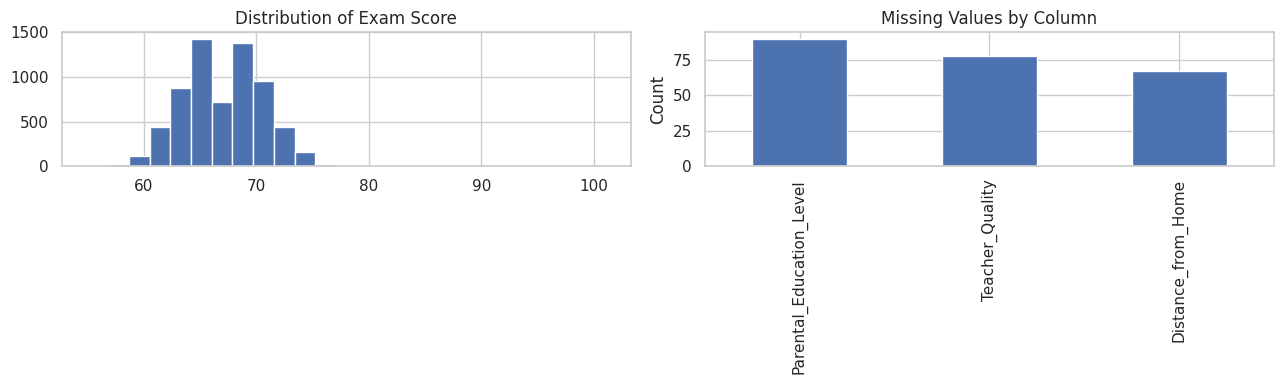

In [5]:
print('各欄位型態及非空值：')
df.info()
print('缺失值統計：')
display(df.isna().sum().rename('Missing').to_frame())
print('重複列數：', df.duplicated().sum())
print('描述性統計：')
display(df.describe(include='all').T)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df['Exam_Score'].dropna(), bins=25, edgecolor='white')
axes[0].set_title('Distribution of Exam Score')
missing = df.isna().sum().sort_values(ascending=False)

if (missing > 0).any():
    missing[missing > 0].plot(kind='bar', ax=axes[1])
else:
    axes[1].text(.5, .5, 'No missing values', ha='center', va='center', transform=axes[1].transAxes)
axes[1].set_title('Missing Values by Column')
axes[1].set_ylabel('Count')
plt.tight_layout()
plt.show()

## 3. Data Preparation（資料準備）

1. 分離 `Exam_Score`（Y）與其他 19 個原始欄位（X）；缺失目標值不參與訓練。
2. **先**切分訓練集 80%／測試集 20%，避免資料洩漏。
3. 數值欄位以訓練集的中位數補值；類別欄位以訓練集眾數補值後 One-Hot Encoding；未知類別採忽略處理。
4. 前處理放在 Pipeline 中，僅在訓練資料 `fit`；測試集只 `transform`。
5. 依原始欄位群組選出 15 項特徵，而非把 One-Hot 展開欄位誤當成原始特徵。

In [6]:
data = df.dropna(subset=['Exam_Score']).copy()
X = data[original_features].copy()
y = pd.to_numeric(data['Exam_Score'], errors='coerce')
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in original_features if c not in num_cols]
print('數值欄位：', num_cols)
print('類別欄位：', cat_cols)
print('原始輸入欄位數：', len(num_cols) + len(cat_cols))
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print('訓練／測試筆數：', len(X_train), len(X_test))

def make_preprocessor(cols):
    ncols = [c for c in cols if c in num_cols]
    ccols = [c for c in cols if c in cat_cols]
    transformers = []
    if ncols:
        transformers.append(('num', SimpleImputer(strategy='median'), ncols))
    if ccols:
        cat_pipe = Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ])
        transformers.append(('cat', cat_pipe, ccols))
    return ColumnTransformer(transformers=transformers, remainder='drop', sparse_threshold=0)

def make_model(cols):
    return Pipeline([
        ('preprocess', make_preprocessor(cols)),
        ('regressor', LinearRegression())
    ])

數值欄位： ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
類別欄位： ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']
原始輸入欄位數： 19
訓練／測試筆數： 5285 1322


### Feature Selection A：SelectKBest 思路（依原始欄位分組）

先在**訓練集**上做缺失值處理及 One-Hot Encoding，計算編碼後各數值欄位對目標的 `f_regression` F 分數。針對每個原始類別欄位，彙整該欄位衍生虛擬變數的**最高 F 分數**，再選原始欄位分數前 15 名。這是群組化的單變量 F 篩選，**不是**直接對 19 個原始欄位呼叫 `SelectKBest`；類別欄位中的最高分彙整是本作業明確定義的選取準則。

In [7]:
# 僅用訓練資料擬合此特徵篩選的前處理。
rank_prep = make_preprocessor(original_features)
Z_train = rank_prep.fit_transform(X_train)
encoded_names = []
raw_mapping = []
if num_cols:
    encoded_names.extend(num_cols)
    raw_mapping.extend(num_cols)
if cat_cols:
    encoder = rank_prep.named_transformers_['cat'].named_steps['onehot']
    all_cat_names = encoder.get_feature_names_out(cat_cols).tolist()
    offset = 0
    for col, cats in zip(cat_cols, encoder.categories_):
        names = all_cat_names[offset:offset + len(cats)]
        encoded_names.extend(names)
        raw_mapping.extend([col] * len(names))
        offset += len(cats)
assert Z_train.shape[1] == len(encoded_names) == len(raw_mapping)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)
    f_scores, p_values = f_regression(Z_train, y_train)
rank_detail = pd.DataFrame({
    'Encoded_Feature': encoded_names,
    'Original_Feature': raw_mapping,
    'F_Score': np.nan_to_num(f_scores, nan=0.0, posinf=0.0, neginf=0.0)
})
group_scores = rank_detail.groupby('Original_Feature')['F_Score'].max().sort_values(ascending=False)
selected_f = group_scores.head(15).index.tolist()
print('編碼後輸入欄位數：', Z_train.shape[1])
print('F 分數方法選出的 15 個原始欄位：', selected_f)
display(group_scores.rename('Max_F_Score').to_frame())
assert len(selected_f) == 15

編碼後輸入欄位數： 40
F 分數方法選出的 15 個原始欄位： ['Attendance', 'Hours_Studied', 'Previous_Scores', 'Tutoring_Sessions', 'Access_to_Resources', 'Parental_Involvement', 'Parental_Education_Level', 'Learning_Disabilities', 'Peer_Influence', 'Family_Income', 'Distance_from_Home', 'Teacher_Quality', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access']


,Max_F_Score
Original_Feature,
Attendance,2664.242099
Hours_Studied,1243.583979
Previous_Scores,162.874873
Tutoring_Sessions,131.985120
Access_to_Resources,119.425433
Parental_Involvement,107.530710
Parental_Education_Level,54.503895
Learning_Disabilities,44.717692
Peer_Influence,39.894517


### Feature Selection B：Permutation Importance（依原始欄位）

先只在訓練集擬合 19 特徵線性迴歸模型，再於**訓練集**打亂每個原始欄位並觀察 MSE 增加量（`neg_mean_squared_error` 分數的下降幅度）。選重要性前 15 個原始特徵；不接觸測試集決定特徵。此數值只是模型依賴程度，不能推論因果關係。

Permutation Importance 選出的 15 個原始欄位： ['Attendance', 'Hours_Studied', 'Access_to_Resources', 'Parental_Involvement', 'Previous_Scores', 'Tutoring_Sessions', 'Family_Income', 'Peer_Influence', 'Parental_Education_Level', 'Motivation_Level', 'Distance_from_Home', 'Teacher_Quality', 'Extracurricular_Activities', 'Learning_Disabilities', 'Internet_Access']


,Importance_MSE_Increase
Attendance,10.322434
Hours_Studied,6.198171
Access_to_Resources,1.055376
Parental_Involvement,0.991694
Previous_Scores,0.965988
Tutoring_Sessions,0.768878
Family_Income,0.346833
Peer_Influence,0.316539
Parental_Education_Level,0.274430
Motivation_Level,0.261575


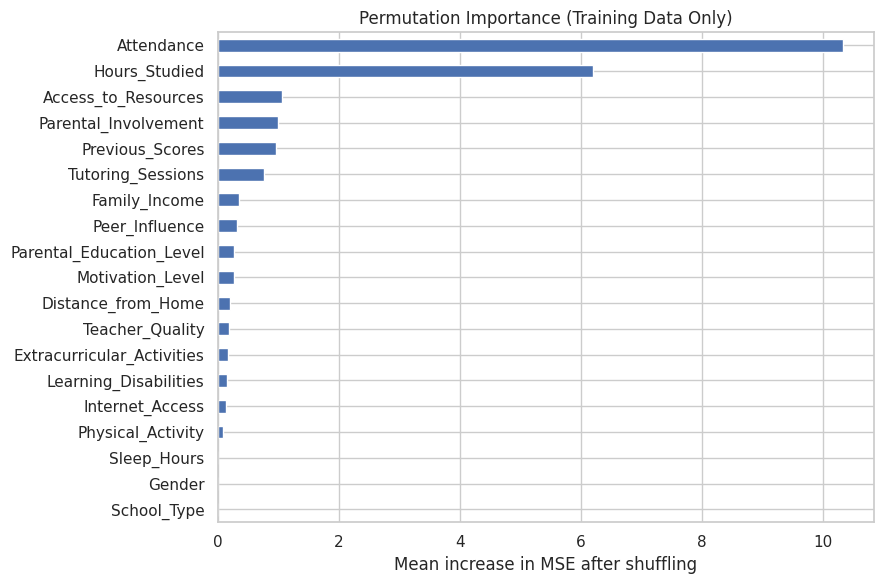

In [8]:
full_model = make_model(original_features)
full_model.fit(X_train[original_features], y_train)
perm = permutation_importance(
    full_model, X_train[original_features], y_train,
    scoring='neg_mean_squared_error', n_repeats=3,
    random_state=RANDOM_STATE, n_jobs=-1
)
perm_scores = pd.Series(perm.importances_mean, index=original_features).sort_values(ascending=False)
selected_perm = perm_scores.head(15).index.tolist()
print('Permutation Importance 選出的 15 個原始欄位：', selected_perm)
display(perm_scores.rename('Importance_MSE_Increase').to_frame())
assert len(selected_perm) == 15
fig, ax = plt.subplots(figsize=(9, 6))
perm_scores.sort_values().plot.barh(ax=ax)
ax.set_title('Permutation Importance (Training Data Only)')
ax.set_xlabel('Mean increase in MSE after shuffling')
plt.tight_layout()
plt.show()

## 4. Modeling（模型建立）

比較三種多元線性迴歸：A 全部 19 個原始特徵、B 群組 F 分數選出的 15 個原始特徵、C Permutation Importance 選出的 15 個原始特徵。類別編碼後的**模型實際係數個數**可能不同於原始欄位數。

In [9]:
feature_sets = {
    'A_All_19': original_features,
    'B_Group_F_Top15': selected_f,
    'C_Permutation_Top15': selected_perm
}
models, predictions, rows = {}, {}, []
for name, cols in feature_sets.items():
    model = make_model(cols)
    model.fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    models[name], predictions[name] = model, pred
    rows.append({
        'Model': name,
        'Original_Features': len(cols),
        'Encoded_Features': model.named_steps['preprocess'].transform(X_train[cols]).shape[1],
        'MAE': mean_absolute_error(y_test, pred),
        'MSE': mean_squared_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2': r2_score(y_test, pred)
    })
results = pd.DataFrame(rows).set_index('Model')
print('測試集評估（模型選擇及特徵篩選都未使用測試集）：')
display(results.round(4))
print('各模型使用的原始特徵：')
for name, cols in feature_sets.items():
    print(f'{name} ({len(cols)}): {cols}')

測試集評估（模型選擇及特徵篩選都未使用測試集）：


,Original_Features,Encoded_Features,MAE,MSE,RMSE,R2
Model,,,,,,
A_All_19,19,40,0.4524,3.2560,1.8044,0.7696
B_Group_F_Top15,15,34,0.5019,3.2856,1.8126,0.7676
C_Permutation_Top15,15,34,0.5019,3.2856,1.8126,0.7676


各模型使用的原始特徵：
A_All_19 (19): ['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']
B_Group_F_Top15 (15): ['Attendance', 'Hours_Studied', 'Previous_Scores', 'Tutoring_Sessions', 'Access_to_Resources', 'Parental_Involvement', 'Parental_Education_Level', 'Learning_Disabilities', 'Peer_Influence', 'Family_Income', 'Distance_from_Home', 'Teacher_Quality', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access']
C_Permutation_Top15 (15): ['Attendance', 'Hours_Studied', 'Access_to_Resources', 'Parental_Involvement', 'Previous_Scores', 'Tutoring_Sessions', 'Family_Income', 'Peer_Influence', 'Parental_Education_Level', 'Motivation_Level', 'Distance_from_Home', 'Teach

In [10]:
# 顯示完整 19 特徵模型的編碼後迴歸係數
best_model = models['A_All_19']
encoded_feature_names = best_model.named_steps['preprocess'].get_feature_names_out()
coefficient_df = pd.DataFrame({'Encoded_Feature': encoded_feature_names, 'Coefficient': best_model.named_steps['regressor'].coef_})
print('截距：', best_model.named_steps['regressor'].intercept_)
display(coefficient_df.sort_values('Coefficient', key=abs, ascending=False))


截距： 39.49932779181265


,Encoded_Feature,Coefficient
10,cat__Access_to_Resources_Low,-1.056906
9,cat__Access_to_Resources_High,1.044244
6,cat__Parental_Involvement_High,1.023711
7,cat__Parental_Involvement_Low,-0.977973
19,cat__Family_Income_High,0.582719
27,cat__Peer_Influence_Negative,-0.539524
14,cat__Motivation_Level_High,0.532356
20,cat__Family_Income_Low,-0.525572
22,cat__Teacher_Quality_High,0.524050
29,cat__Peer_Influence_Positive,0.512149


## 5. Evaluation（模型評估）

MAE、MSE、RMSE 越小越好；R² 越大通常代表較佳測試集預測表現，可能為負。比較三種模型的預測結果與殘差，並檢視基本線性迴歸診斷圖。若以測試集挑最佳模型，報告中應註明它僅是本次比較，正式調參應另設驗證集或交叉驗證。

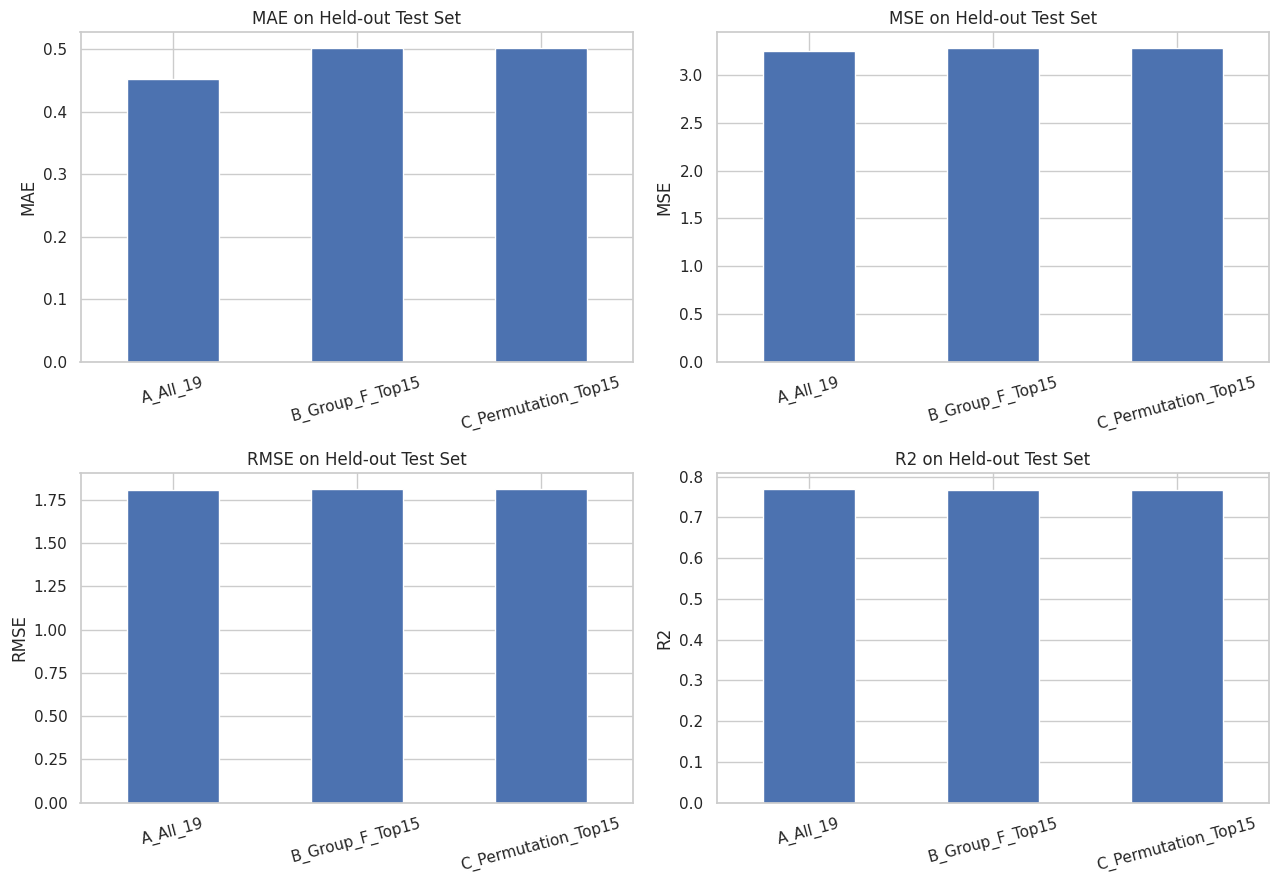

In [11]:
# 三模型評估指標視覺化
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, metric in zip(axes.ravel(), ['MAE', 'MSE', 'RMSE', 'R2']):
    results[metric].plot.bar(ax=ax, rot=15)
    ax.set_title(metric + ' on Held-out Test Set')
    ax.set_xlabel('')
    ax.set_ylabel(metric)
plt.tight_layout()
plt.show()

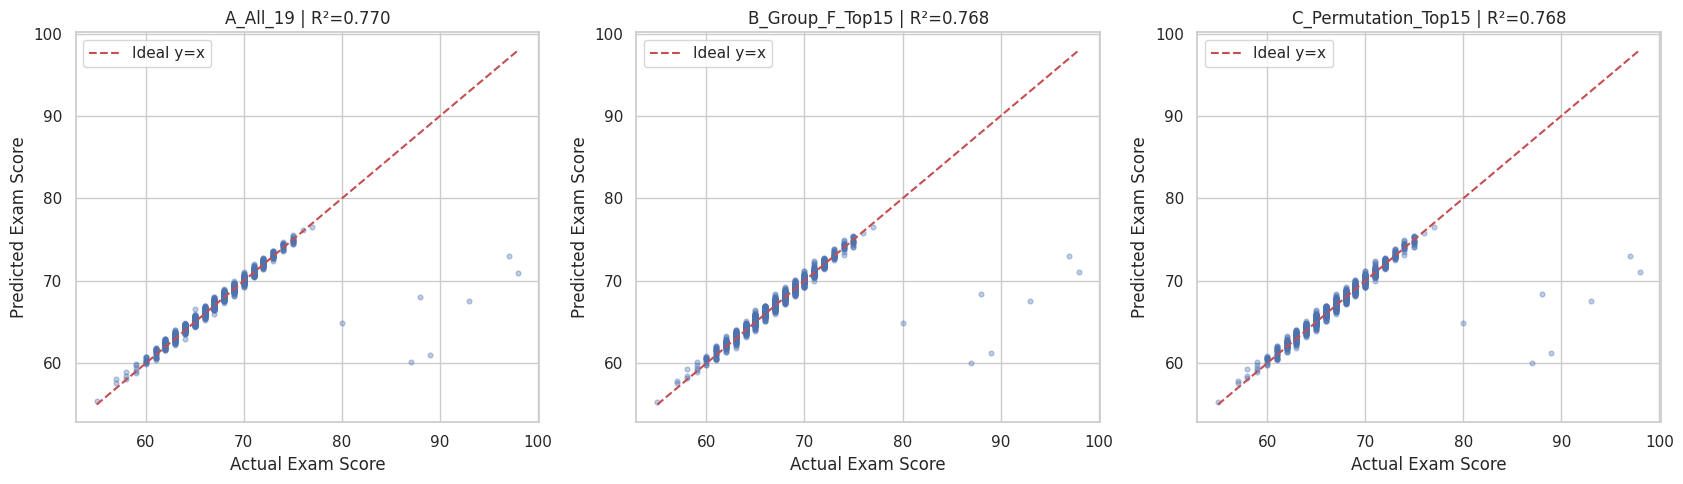

In [12]:
# 真實值 vs 預測值：三組模型並列
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
all_values = np.concatenate([y_test.to_numpy()] + list(predictions.values()))
lo, hi = all_values.min(), all_values.max()
for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, alpha=.35, s=12)
    ax.plot([lo, hi], [lo, hi], 'r--', label='Ideal y=x')
    ax.set(title=f'{name} | R²={r2_score(y_test, pred):.3f}',
           xlabel='Actual Exam Score', ylabel='Predicted Exam Score')
    ax.legend()
plt.tight_layout()
plt.show()

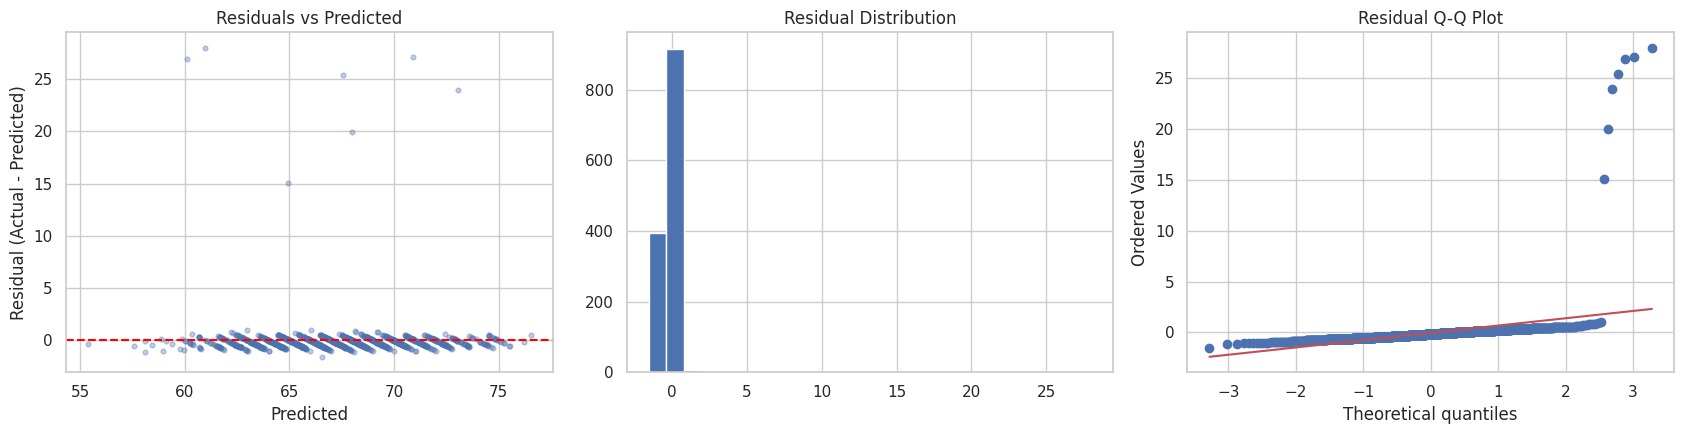

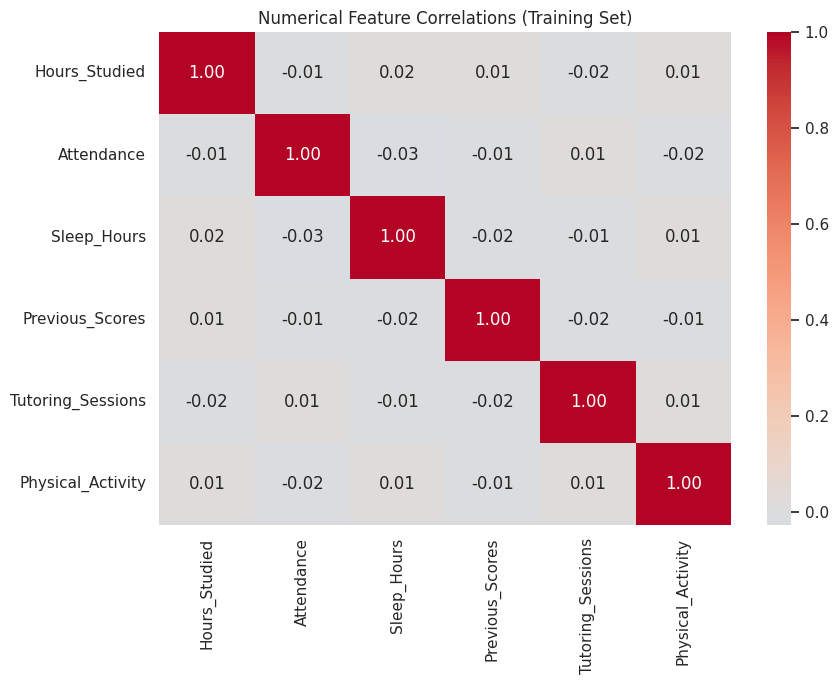

提醒：線性、獨立性、常態性、等變異與共線性假設需搭配研究脈絡及診斷圖討論；圖形本身不能保證假設成立。


In [13]:
# 殘差診斷：殘差 vs 預測、殘差分布、Q-Q 圖與訓練資料相關係數熱圖
from scipy import stats
# 用測試集繪圖描述誤差，不用其數值重新調整特徵。
name = 'A_All_19'
pred = predictions[name]
residuals = y_test.to_numpy() - pred
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(pred, residuals, alpha=.35, s=12)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set(xlabel='Predicted', ylabel='Residual (Actual - Predicted)', title='Residuals vs Predicted')
axes[1].hist(residuals, bins=25, edgecolor='white')
axes[1].set_title('Residual Distribution')
stats.probplot(residuals, dist='norm', plot=axes[2])
axes[2].set_title('Residual Q-Q Plot')
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(X_train[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Numerical Feature Correlations (Training Set)')
plt.tight_layout()
plt.show()
print('提醒：線性、獨立性、常態性、等變異與共線性假設需搭配研究脈絡及診斷圖討論；圖形本身不能保證假設成立。')

In [14]:
# 輸出評估表與測試集預測（可在 Colab 左側檔案下載）
results.to_csv('hw2_model_comparison.csv', encoding='utf-8-sig')
prediction_table = pd.DataFrame({'Actual_Exam_Score': y_test.to_numpy()})
for name, pred in predictions.items():
    prediction_table[name + '_Predicted'] = pred
prediction_table.to_csv('hw2_test_predictions.csv', index=False, encoding='utf-8-sig')
display(prediction_table.head(10).round(2))
print('已產生 hw2_model_comparison.csv 與 hw2_test_predictions.csv')

,Actual_Exam_Score,A_All_19_Predicted,B_Group_F_Top15_Predicted,C_Permutation_Top15_Predicted
0,65,64.53,64.14,64.14
1,65,65.27,65.43,65.43
2,71,71.53,71.49,71.49
3,64,64.28,64.11,64.11
4,66,66.52,66.12,66.12
5,66,66.61,66.66,66.66
6,72,72.47,72.06,72.06
7,66,66.50,66.51,66.51
8,70,69.99,69.98,69.98
9,70,70.13,70.33,70.33


已產生 hw2_model_comparison.csv 與 hw2_test_predictions.csv


## 6. Deployment（模型應用示範）

使用全 19 個原始特徵模型，將**訓練集一筆資料作為欄位格式示範**，再預測其考試成績。正式應用時可替換為真正的新學生資料（須提供全部原始欄位，且欄位與訓練時一致）。此處只演示流程，**未正式部署**。

In [15]:
example_input = X_train[original_features].iloc[[0]].copy()  # 僅作輸入格式示範
example_prediction = models['A_All_19'].predict(example_input)[0]
print('示範輸入（來自訓練集的既有紀錄，不是新學生）：')
display(example_input.T.rename(columns={example_input.index[0]: 'Example_Value'}))
print('模型示範預測分數：', round(float(example_prediction), 2))

示範輸入（來自訓練集的既有紀錄，不是新學生）：


,Example_Value
Hours_Studied,27
Attendance,79
Parental_Involvement,Low
Access_to_Resources,High
Extracurricular_Activities,Yes
Sleep_Hours,8
Previous_Scores,63
Motivation_Level,High
Internet_Access,Yes
Tutoring_Sessions,2


模型示範預測分數： 68.72
